# 1. Initial setup
---
Installing dependencies and libraries as well as autoreloading modules and third-parties

In [21]:
# Installing dependencies for the analysis
%pip install pandas matplotlib openpyxl

Note: you may need to restart the kernel to use updated packages.


In [140]:
%reload_ext autoreload
%autoreload 2

# Importing all modules
import pandas as pd
import matplotlib as mlt
import matplotlib.pyplot as plt
import openpyxl as xl
from openpyxl import load_workbook
import math
from openpyxl.styles import PatternFill
from visualise import *

# Additional variables
SEVERITY = {
    'F8CBAD':'high', 
    'FEF802':'medium', 
    '92D050':'low', 
    'BDD7EE':'info', 
    'F60000':'critical', 
    '000000': None,
    'AEAAAA':'false_positives'
}

# 2. Data Cleaning
---

Clean the dataset to make sure the data points are consistent and accurate before proceeding. I guess it's a good practice to use `openpyxl` to make the cleaning process possible.

## I1 - Normalise all severity colors within the `New Bugs` sheet
Some of the cells possess a mismatch in color, such as using a theme/tint color. This can introduce difficulties comparing and evaluating severities later on.

In [78]:
PATH="Results.xlsx"
wb = load_workbook(PATH, data_only=True)
NBUGS = wb["New bugs"]

In [104]:
# Normalise the severity rating colors

RESULTS.iloc[1:33, 3:13].stack().unique()
for row in NBUGS.iter_rows(min_row=3, max_row=51, min_col=2, max_col=14):
    for cell in row:
        color = cell.fill.fgColor

        if (
            color.type == "theme"
            and color.theme == 5
            and abs((color.tint or 0) - 0.5999) < 0.0001
        ):
            cell.fill = PatternFill(fill_type="solid", fgColor="F8CBAD")

wb.save("Results.I1.xlsx")

# Ensuring that all colors are valid now
PATH="Results.I1.xlsx"
wb = load_workbook(PATH, data_only=True)
NBUGS = wb["New bugs"]
for row in NBUGS.iter_rows(min_row=3, max_row=51, min_col=2, max_col=14):
    for cell in row:
        color = cell.fill.fgColor
        if color.type=="theme":
            raise Exception("Invalid severity color")
        elif color.type=="rgb":
            colorRgb = color.rgb[2:]
            SEVERITY[colorRgb]
print("OK")

OK


## I2 - Lowercase all severities within the `Results` sheet.
Just to make everything consistent according to a common format, I will lowercase all severities and check for any malformed data points within the dataset

In [115]:
PATH="Results.I1.xlsx"

wb = load_workbook(PATH)
RESULTS = wb["Results"]

unique_values = set()

for row in RESULTS.iter_rows(min_row=2, max_row=33, min_col=4, max_col=13):
    for cell in row:
        # Lowercase hardcoded text only; leave formulas, numbers, colours, etc. unchanged
        if isinstance(cell.value, str):
            unique_values.add(cell.value.lower())
            cell.value = cell.value.lower()
            
wb.save("Results.Final.xlsx")
print(unique_values)

{'info', 'critical', 'low', 'high', 'medium'}


# 3. Data transformation
---
The section below is dedicated to transforming and converting the dataset into a collection of easily representative visualisations. The point is to construct sub-datasets suitable for the following purposes:

1. Efficiency evaluation between LLMs
2. Consistency evaluation between LLMs
3. Additional findings

In [194]:
# Run this first
import re

PATH="Results.Final.xlsx"

# DataFrames to be manipulated
df_cost = pd.read_excel(PATH, sheet_name="LLM cost")
df_results = pd.read_excel(PATH, sheet_name="Results")

## 3.1 Data subset for time taken per LLM

In [132]:
def time_to_minutes(value):
    # Convert "00m 00s" to minute in floating point
    match = re.fullmatch(r"\s*(?:(\d+(?:\.\d+)?)m)?\s*(?:(\d+(?:\.\d+)?)s)?\s*",str(value),)
    if not match:
        raise ValueError(f"Invalid time format: {value!r}")
    return float(match.group(1) or 0) + float(match.group(2) or 0) / 60

df_cost_time = df[["Model", "Time"]].copy().dropna()
df_cost_time["Time"] = df_cost_time["Time"].apply(time_to_minutes)
TIME_ITERATIONS = {
    "Claude":df_cost_time.loc[9:17, "Time"],
    "DeepSeek":df_cost_time.loc[0:8, "Time"],
    "Grok":df_cost_time.loc[18:26, "Time"]
}
TIME_ITERATIONS

{'Claude': 9      67.566667
 10     56.750000
 11     46.883333
 12     64.300000
 13     63.350000
 14     24.466667
 15     90.466667
 16    117.750000
 17     62.200000
 Name: Time, dtype: float64,
 'DeepSeek': 0    34.083333
 1    36.583333
 2    74.250000
 3    31.783333
 4    20.483333
 5    36.500000
 6    35.800000
 7    43.633333
 8    27.916667
 Name: Time, dtype: float64,
 'Grok': 18     39.033333
 19     38.716667
 20    124.316667
 21     40.483333
 22     38.766667
 23     35.300000
 24     50.416667
 25    655.716667
 26     28.316667
 Name: Time, dtype: float64}

## 3.2 Data subset for cost taken per LLM

In [136]:
COST_ITERATIONS = {
    "Claude":df_cost.loc[9:17, "Cost (AUD)"],
    "DeepSeek":df_cost.loc[0:8, "Cost (AUD)"],
    "Grok":df_cost.loc[18:26, "Cost (AUD)"]
}
COST_ITERATIONS

{'Claude': 9     14.154
 10    14.266
 11    13.594
 12    14.672
 13    19.978
 14    16.716
 15    13.818
 16    14.686
 17    12.180
 Name: Cost (AUD), dtype: float64,
 'DeepSeek': 0     1.022
 1     1.092
 2     1.288
 3     0.588
 4    15.652
 5     0.672
 6     0.994
 7     0.952
 8     0.630
 Name: Cost (AUD), dtype: float64,
 'Grok': 18    4.858
 19    4.928
 20    4.326
 21    4.802
 22    6.188
 23    4.718
 24    9.716
 25    4.200
 26    3.808
 Name: Cost (AUD), dtype: float64}

## 3.3 Data subset for benchmarking expected findings between LLMs

In [212]:
from collections import defaultdict

benchmark_data = {
    "valid": [
        df_results[col].notna().sum(),
        df_results[col].notna().sum()
        
    ],
    "invalid": [],
    "missbugs": [
        df_results[col].notna().sum(),
        #     row["Claude Opus 4.7 I1"]
#     row["Claude Opus 4.7 I2"]
#     row["Claude Opus 4.7 I3"]
#     row["DeepSeek V4 Pro I2"]
#     row["DeepSeek V4 Pro I3"]
#     row["DeepSeek V4 Pro I1"]
#     row["Grok 4.6 I1"]
#     row["Grok 4.6 I2"]
#     row["Grok 4.6 I3"]
    ]
}

# for index,row in df_results.iterrows():
#     row["Claude Opus 4.7 I1"]
#     row["Claude Opus 4.7 I2"]
#     row["Claude Opus 4.7 I3"]
#     row["DeepSeek V4 Pro I2"]
#     row["DeepSeek V4 Pro I3"]
#     row["DeepSeek V4 Pro I1"]
#     row["Grok 4.6 I1"]
#     row["Grok 4.6 I2"]
#     row["Grok 4.6 I3"]
#     # print(row["Severity"])
# print(df_results.iterrows())
df_results["Grok 4.6 I3"].isna().sum()

np.int64(23)

# 4. Visualisation / Analysis
---
Extracting core details on what insights we can have and analyse from these visualisations between `Claude Opus 4.7`, `DeepSeek V4 Pro` and `Grok 4.6`.

## 4.1 Benchmark expected findings rate between LLMs
Which model performs best when it comes to finding intentional bugs and whether the severity rating is accurate.

> `QUESTION`: How many matched the severity rating, how many didn’t and how many missed the intended bugs ?

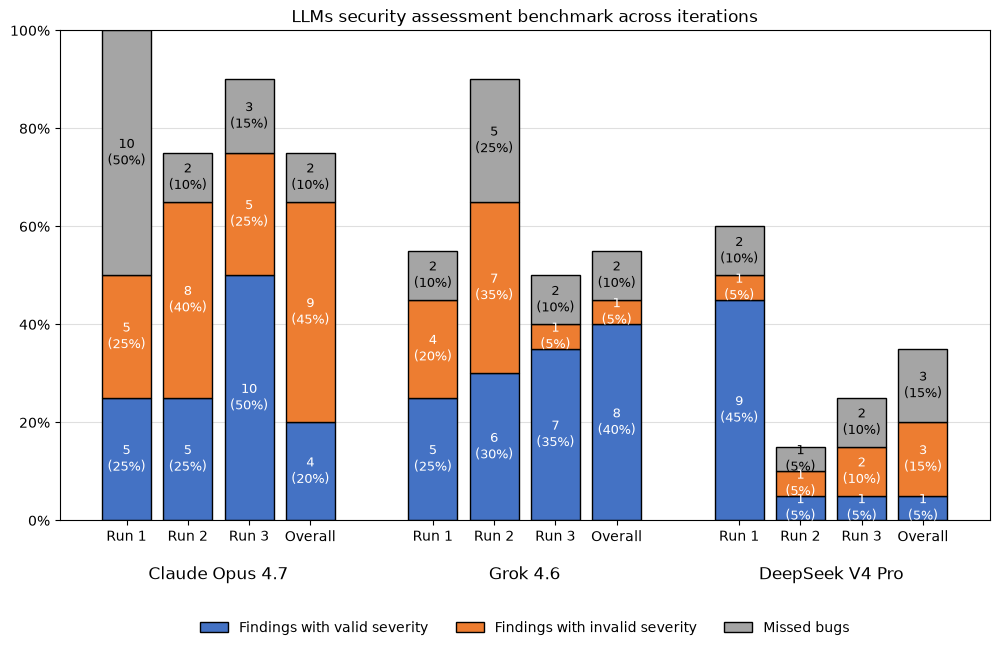

(<Figure size 1200x700 with 1 Axes>,
 <Axes: title={'center': 'LLMs security assessment benchmark across iterations'}>)

In [103]:
years = ["Claude Opus 4.7", "Grok 4.6", "DeepSeek V4 Pro"]
regions = ["Run 1", "Run 2", "Run 3", "Overall"]

data = {
    "Findings with valid severity":  [5, 5, 10, 4, 5, 6,7,8,9,1,1,1],
    "Findings with invalid severity": [5, 8, 5, 9, 4, 7,1,1,1,1,2,3],
    "Missed bugs": [10, 2, 3, 2, 2, 5,2,2,2,1,2,3],
}

stacked_bar_groups_percent(
    years,
    regions,
    data,
    total=20,
    title="LLMs security assessment benchmark across iterations"
)

## 4.1 Which LLMs discover the most new bugs ?

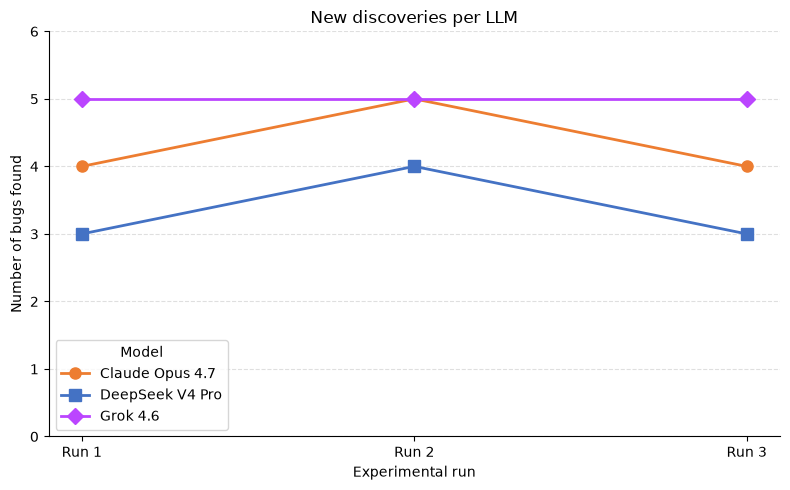

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'New discoveries per LLM'}, xlabel='Experimental run', ylabel='Number of bugs found'>)

In [97]:
results = {
    "Claude Opus 4.7": [4, 5, 4],
    "DeepSeek V4 Pro": [3, 4, 3],
    "Grok 4.6": [5, 5, 5],
}

plot_bugs_per_run(results, y_max=6, title="New discoveries per LLM")

## 4.2 Benchmark the capabilities to discover new bugs between LLMs

Which model experiences the most false-positives / hallucinations, out-of-scoped items, bug uniqueness, and severity correctness.

> `QUESTION`: Across all overlapping bugs, which model possesses the highest rate of bug uniqueness across three flagship models. This means which one among them manages to discover bugs that are completely unique to the rest, where the other two models failed to discover such findings ? Additionally, talk about the severity of those bugs as well.

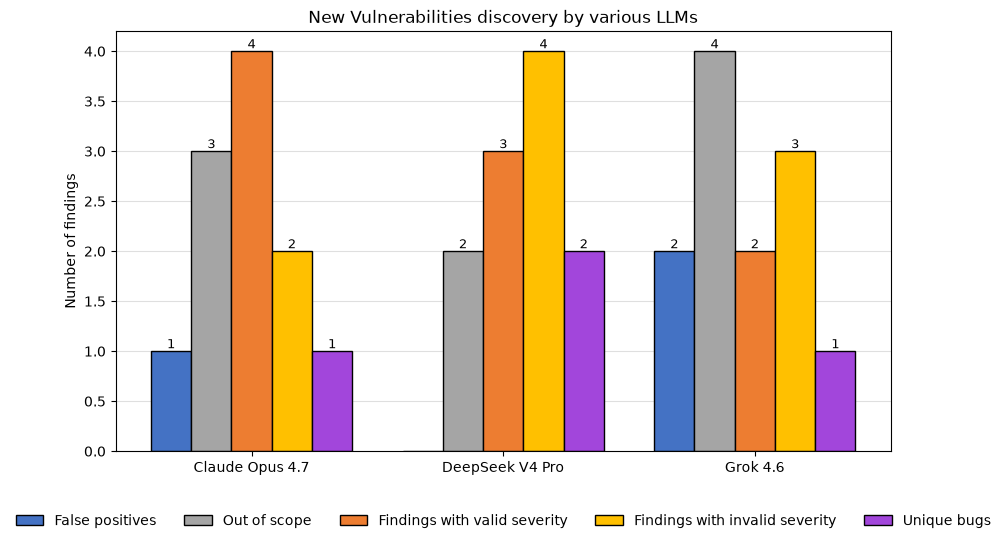

In [191]:
groups = ["Claude Opus 4.7", "DeepSeek V4 Pro", "Grok 4.6"]

data = {
    "False positives": [1, 0, 2],
    "Out of scope":     [3, 2, 4],
    "Findings with valid severity":   [4, 3, 2],
    "Findings with invalid severity":      [2, 4, 3],
    "Unique bugs":     [1, 2, 1],
}

fig, ax = grouped_bar_chart(
    groups=groups,
    data=data,
    title="New Vulnerabilities discovery by various LLMs"
)

## 4.2 Benchmark the cost between LLMs

Which model produces the cheapest cost overall, as well as the average cost ?

> INCIDENT: The outlier for DeepSeek V4 Pro was actually an incident where DeepSeek hang forever whilst during the second iteration of company 3. It wiped out the balance and took over 15.652$ AUD and had to be manually stopped before retrying again. 

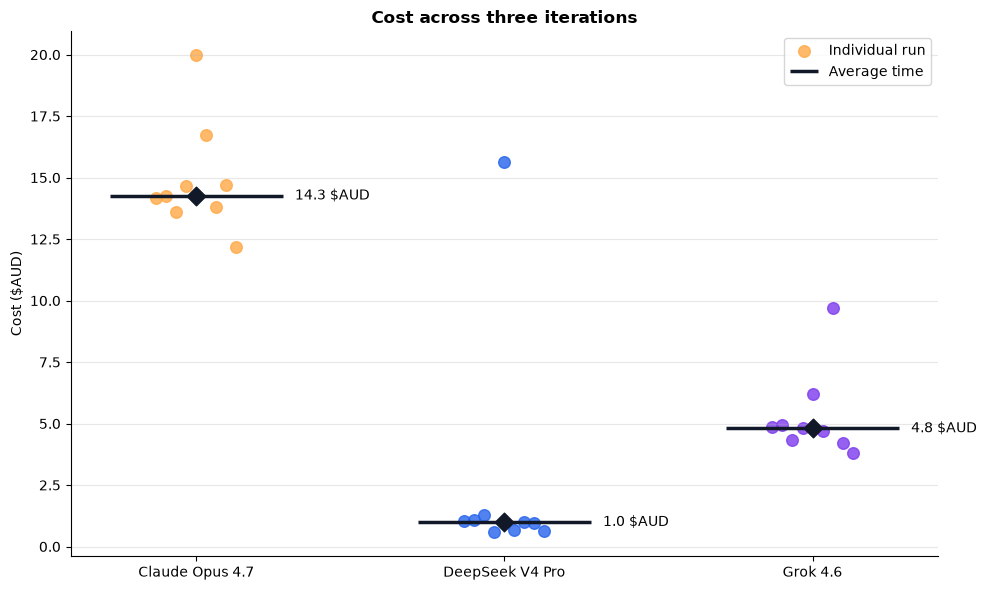

In [146]:
times = {
    "Claude Opus 4.7": COST_ITERATIONS["Claude"],
    "DeepSeek V4 Pro": COST_ITERATIONS['DeepSeek'],
    "Grok 4.6": COST_ITERATIONS['Grok'],
}

plot_dot_with_median(times, "Cost across three iterations", "Cost ($AUD)", unit="$AUD")

## 4.2 Benchmark the time taken between three iterations per LLM

Which model takes the longest time to complete an assessment.

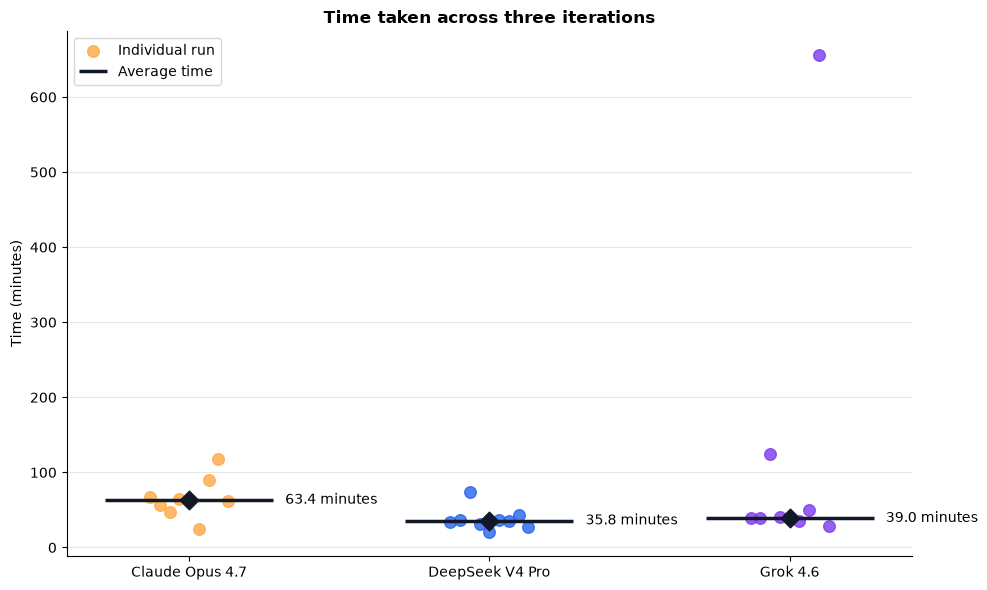

In [145]:
times = {
    "Claude Opus 4.7": TIME_ITERATIONS["Claude"],
    "DeepSeek V4 Pro":  TIME_ITERATIONS["DeepSeek"],
    "Grok 4.6":  TIME_ITERATIONS["Grok"],
}

plot_dot_with_median(times, "Time taken across three iterations", "Time (minutes)", unit="minutes")

## 4.3 Consistency evaluation across iterations for each LLM 
Checking the consistency of vulnerabilities discovery, their severity consistency and known-bug recall rate. This can be calculated based on the previous dataset using the following formulas:

$$
\text{Known-Bug Recall}_{m,r} =
\frac{|F_{m,r} \cap K|}{|K|}
\times 100
$$

$$
\text{Discovery Consistency}_{m} =
\frac{1}{|B|}
\sum_{b \in B}
\text{Discovery Consistency}_{m,b}
$$


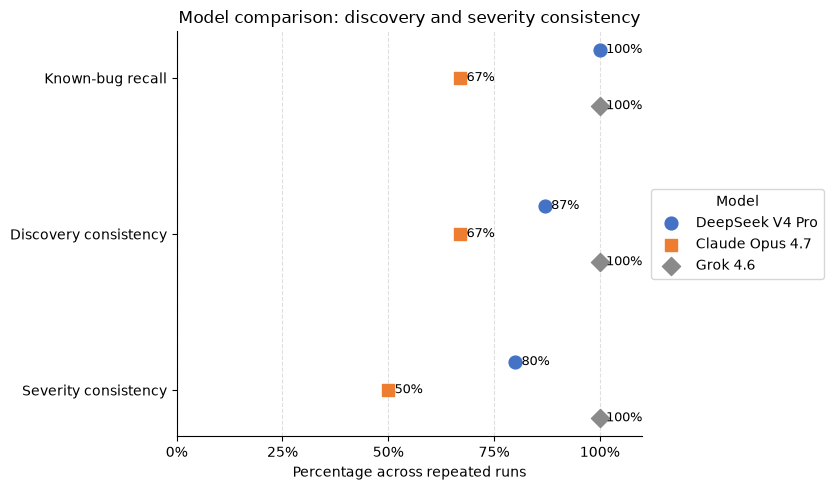

(<Figure size 1000x500 with 1 Axes>,
 <Axes: title={'center': 'Model comparison: discovery and severity consistency'}, xlabel='Percentage across repeated runs'>)

In [70]:
metrics = {
    "Known-bug recall": {
        "DeepSeek V4 Pro": 100,
        "Claude Opus 4.7": 67,
        "Grok 4.6": 100,
    },
    "Discovery consistency": {
        "DeepSeek V4 Pro": 87,
        "Claude Opus 4.7": 67,
        "Grok 4.6": 100,
    },
    "Severity consistency": {
        "DeepSeek V4 Pro": 80,
        "Claude Opus 4.7": 50,
        "Grok 4.6": 100,
    },
}

plot_model_summary(metrics)

## 4.3 Consistency evaluation across iterations for each LLM (new bugs)
Checking the consistency of new discoveries as well as their severity.

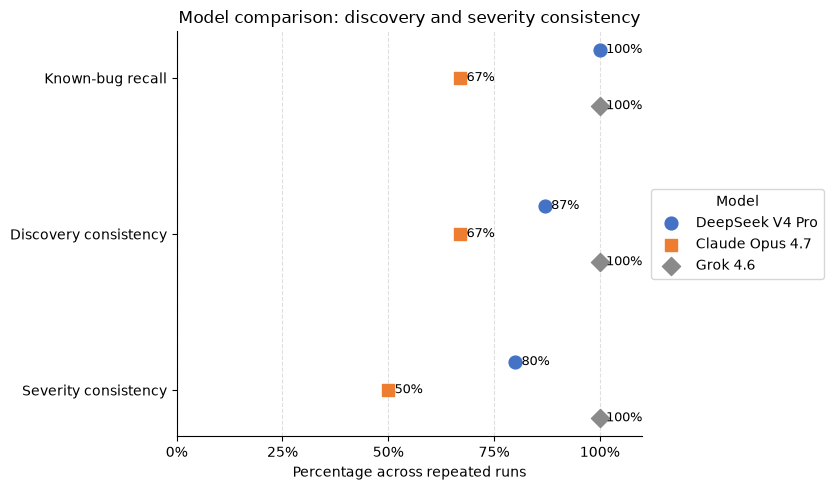

(<Figure size 1000x500 with 1 Axes>,
 <Axes: title={'center': 'Model comparison: discovery and severity consistency'}, xlabel='Percentage across repeated runs'>)

In [70]:
metrics = {
    "Known-bug recall": {
        "DeepSeek V4 Pro": 100,
        "Claude Opus 4.7": 67,
        "Grok 4.6": 100,
    },
    "Discovery consistency": {
        "DeepSeek V4 Pro": 87,
        "Claude Opus 4.7": 67,
        "Grok 4.6": 100,
    },
    "Severity consistency": {
        "DeepSeek V4 Pro": 80,
        "Claude Opus 4.7": 50,
        "Grok 4.6": 100,
    },
}

plot_model_summary(metrics)

# 5 Additional findings
---
Not what relevant to the above but more like insights collected from the dataset

1. There was one outlier in Grok 4.6 during iteration 2 of company `AuSecurity` where it took over 600 minutes.
2. There was one outlier in DeepSeek V4 Pro during Iteration 2 of the company `Imagur` where it costed over 15 dollars and was hanging over night during the assessment. I had to manually stop the assessment and restarted it. 